# Neural Green's Operators (NGOs) for the time-dependent diffusion problem

Before running this notebook, be sure you installed the right packages according to the README.md. Running this notebook from top to bottom should give you within a few seconds a reasonably accurate trained model NGO, a plot of a true solution versus the model NGO prediction, and a plot of the prediction error of the model NGO versus the length scale of the test data. For higher accuracy, set the variables 'N_samples_train'=10000, 'N_samples_val'=1000 and 'epochs'=5000. For higher statistics in the error versus length scale plot, set the number of test data samples to 100 or 1000.

### Imports

In [1]:
from ngo.ml.trainer import train
from ngo.ml.customlosses import *
from ngo.ml.systemnets import *
from ngo.numericalanalysis.basisfunctions import *
from ngo.ml.modelloader import *
from ngo.numericalanalysis.quadrature import *
from ngo.testproblems.timedependentdiffusion.NeuralOperator import NeuralOperator
from ngo.testproblems.timedependentdiffusion.DataModule import DataModule
from ngo.testproblems.timedependentdiffusion.manufacturedsolutions import *
import matplotlib.pyplot as plt
from ngo.numericalanalysis.linalg import *
hparams = {}

/home/prins/st7/my_venv/lib/python3.13/site-packages/lightning_fabric/__init__.py:41: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


### Data type and device

In [2]:
hparams['dtype'] = torch.float64 #Model dtype
hparams['accelerator'] = 'gpu' # Can be set to 'cpu' if desired
hparams['device'] = 'cuda:0' # Can be set to 'cpu' if desired

### Training data (manufactured solutions)

In [3]:
#Training data
hparams['N_samples_train'] = 1000 #Number of training samples
hparams['N_samples_val'] = 100 #Number of validation samples
hparams['l_min'] = torch.tensor([0.5,0.5,0.5], dtype=hparams['dtype'], device=hparams['device']) #Minimum GRF length scale per dimension
hparams['l_max'] = torch.tensor([1,1,1], dtype=hparams['dtype'], device=hparams['device']) #Maximum GRF length scale per dimension
hparams['d'] = len(hparams['l_min']) #Number of spatial dimensions
hparams['b_theta_min'] = 1 #minimum coefficient field mean
hparams['b_theta_max'] = 1 #maximum coefficient field mean
hparams['c_theta_min'] = 0 #minimum coefficient field standard deviation
hparams['c_theta_max'] = 0.2 #maximum coefficient field standard deviation
hparams['b_u_min']  = -1 #minimum solution field mean   
hparams['b_u_max']  = 1 #maximum solution field mean
hparams['c_u_min']  = 0 #minimum solution field standard deviation
hparams['c_u_max']  = 1 #maximum solution field standard deviation
hparams['n_RBF'] = (5,5,5) #Number of basis functions per dimension for data generation

### Training settings

In [4]:
hparams['output_coefficients'] = True #Whether the NN outputs coefficients (True) or values at quadrature points (False)
hparams['solution_loss'] = relativeL2norm_coefficients #For data NGO and model NGO. See src/ngo/ml/customlosses.py for the options
hparams['matrix_loss'] = None #Option: "relativematrixnorm" for data-free NGO
hparams['metric'] = relativeL2norm_coefficients
hparams['optimizer'] = torch.optim.Adam
hparams['learning_rate'] = 1e-3
hparams['batch_size'] = 100
hparams['epochs'] = 100 #Default for model NGO is 5000, for data NGO 20000

### Bases


In [5]:
hparams['N_i'] = (2,10,10) #Number of basis functions per dimension
hparams['p'] = (1,3,3) #Polynomial order per dimension (in case of B-spline basis)
hparams['C'] = (0,2,2) #Continuity along elements per dimension (in case of B-spline basis)
hparams['N'] = np.prod(hparams['N_i']) #Number of  basis degrees of freedom
hparams['test_bases'] = [BSplineBasis(N=hparams['N_i'][0], p=hparams['p'][0], C=hparams['C'][0], dtype=hparams['dtype'], device=hparams['device']), #basis functions in t
                         BSplineBasis(N=hparams['N_i'][1], p=hparams['p'][1], C=hparams['C'][1], dtype=hparams['dtype'], device=hparams['device']), #basis functions in x
                         BSplineBasis(N=hparams['N_i'][2], p=hparams['p'][2], C=hparams['C'][2], dtype=hparams['dtype'], device=hparams['device'])] #basis functions in y (see src/ngo/ml/basisfunctions.py for the options)
hparams['trial_bases'] = [BSplineBasis(N=hparams['N_i'][0], p=hparams['p'][0], C=hparams['C'][0], dtype=hparams['dtype'], device=hparams['device']), #basis functions in t
                         BSplineBasis(N=hparams['N_i'][1], p=hparams['p'][1], C=hparams['C'][1], dtype=hparams['dtype'], device=hparams['device']), #basis functions in x
                         BSplineBasis(N=hparams['N_i'][2], p=hparams['p'][2], C=hparams['C'][2], dtype=hparams['dtype'], device=hparams['device'])] #basis functions in y (see src/ngo/ml/basisfunctions.py for the options)
hparams['Dt'] = 0.001 #Time step size

### Quadrature

In [6]:
hparams['quadrature'] = 'Gauss-Legendre' #Quadrature rule, either "Gauss-Legendre" or "uniform" (for FNO)
hparams['n_elements'] = (1,3,3) #Number of elements of the quadrature grid
hparams['Q'] = (2,99,99) #Number of quadrature points per dimension (for all elements, not per element)
hparams['quadrature_L'] = 'Gauss-Legendre' #Loss quadrature rule, either "Gauss-Legendre" or "uniform" (for FNO)
hparams['n_elements_L'] = (1,3,3) #Number of elements of the loss quadrature grid
hparams['Q_L'] = (2,99,99) #Number of loss quadrature points per dimension (for all elements, not per element)

### System net

In [7]:
hparams['modeltype'] = 'data NGO' #Options: "NN" for bare NN, "DeepONet", "VarMiON", "data NGO", "model NGO"
hparams['systemnet'] = CNN_3dto2d #See src/ngo/ml/systemnets.py for the options
hparams['N_w'] = 30000 #Number of trainable parameters (upper bound, not exact)
hparams['bias'] = False
hparams['skipconnections'] = True #In case of a symmetric CNN -> U-Net
# hparams['kernel_sizes'] = [2,2,5,10,10,5,2,2] #In case of a CNN. See paper appendix for kernel sizes for all different models
hparams['kernel_sizes'] = [(1,1,1), (1,1,1), (1,2,2), (2,5,5), (5,5), (2,2), (1,1), (20,20)] #In case of a CNN. See paper appendix for kernel sizes for all different models
hparams['bottleneck_size'] = 20 #MLP bottleneck size in case of a CNN (uses an MLP connection in the bottleneck)
hparams['outputactivation'] = nn.Tanhshrink() #Set to None for models other than model NGO. For the systemnet. Hidden layer activations are ReLU by default

### Additional inductive bias

In [8]:
hparams['Neumannseries'] = False #Whether to use Neumann series expansion (only for model NGOs and data-free NGOs)
hparams['Neumannseries_order'] = 1 #Order of the Neumann series expansion (only for model NGOs and data-free NGOs)
hparams['scaling_equivariance'] = False #Whether to use scaling equivariance (only for NGOs)
hparams['Mnorm_scaling'] = False #Whether to scale the system matrix norm during training (only for data NGO)
hparams['Mnorm_max'] = 0.8 #Target maximum system matrix norm (only for data NGO)
hparams['tol'] = 1e-3 #Power iteration tolerance for estimating the system matrix norm (only for data NGO)
hparams['max_iterations'] = 1000 #Power iteration max. number of iterations for estimating the system matrix norm (only for data NGO)
hparams['alpha'] = 0 #Dissipation parameter (set to 0 by default)
hparams['gamma_stabilization'] = 100 #Stabilization constant for the system matrix
hparams['massconservation'] = False #Whether to enforce mass conservation
hparams['dissipation'] = False #Whether to enforce a dissipation
hparams['stabilization_in_massconservation'] = False #Whether to include the stabilization term in the mass conservation constraint

In [9]:
logdir = './nnlogs' #Location for the tensorboard log files
sublogdir = 'tdd' #Folder name in the "nnlogs" directory
label = 'ngo_single' #Give your model a name
hparams['logdir'] = logdir+'/'+sublogdir+'/'+label
hparams['label'] = label

In [10]:
ngo = NeuralOperator(hparams)

/data/storage7/prins/git/ngo-pde-gk/src/ngo/testproblems/timedependentdiffusion/NeuralOperator.py:112: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x_0 = torch.tensor(x_0, dtype=self.dtype, device=self.device)


In [11]:
ngo.assemble_M_i()

(tensor([[[0.0003, 0.0002],
          [0.0002, 0.0003]]], device='cuda:0', dtype=torch.float64),
 tensor([[[2.0408e-02, 1.2500e-02, 2.6360e-03, 1.7004e-04, 0.0000e+00,
           0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [1.2500e-02, 3.1633e-02, 2.2322e-02, 4.9320e-03, 4.2510e-05,
           0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [2.6360e-03, 2.2322e-02, 4.6683e-02, 3.2086e-02, 3.3872e-03,
           2.8342e-05, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [1.7004e-04, 4.9320e-03, 3.2086e-02, 6.8481e-02, 3.3759e-02,
           3.4014e-03, 2.8344e-05, 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [0.0000e+00, 4.2510e-05, 3.3872e-03, 3.3759e-02, 6.8481e-02,
           3.3759e-02, 3.4014e-03, 2.8342e-05, 0.0000e+00, 0.0000e+00],
          [0.0000e+00, 0.0000e+00, 2.8342e-05, 3.4014e-03, 3.3759e-02,
           6.8481e-02, 3.3759e-02, 3.3872e-03, 4.2510e-05, 0.0000e+00],
          [0.0000e+00, 0.0000e+00, 0.0000e+00

In [14]:
kron(ngo.assemble_M_rr_i()).shape

torch.Size([1, 200, 200])

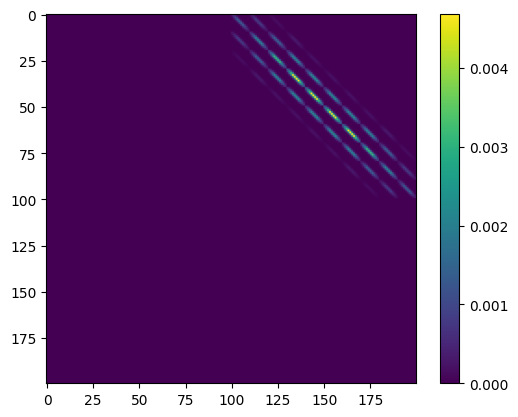

In [20]:
plt.imshow(kron(ngo.assemble_M_lr_i())[0].cpu())
plt.colorbar()